### PyDicom

In [45]:
import pydicom
import matplotlib.pyplot as plt
import numpy as np

In [101]:
dcm = pydicom.dcmread('/Users/Isa/Documents/Curso Medical Image Processing/data/sitk/digital_xray.dcm')
dcm

Dataset.file_meta -------------------------------
(0002,0000) File Meta Information Group Length  UL: 204
(0002,0001) File Meta Information Version       OB: b'\x00\x01'
(0002,0002) Media Storage SOP Class UID         UI: Secondary Capture Image Storage
(0002,0003) Media Storage SOP Instance UID      UI: 2.25.225981116244996633889747723103230447077
(0002,0010) Transfer Syntax UID                 UI: JPEG Baseline (Process 1)
(0002,0012) Implementation Class UID            UI: 1.3.6.1.4.1.30071.8
(0002,0013) Implementation Version Name         SH: 'fo-dicom 3.0.2'
(0002,0016) Source Application Entity Title     AE: 'DUB-IB-TBDAT-01'
-------------------------------------------------
(0008,0005) Specific Character Set              CS: 'ISO_IR 100'
(0008,0012) Instance Creation Date              DA: '20180713'
(0008,0013) Instance Creation Time              TM: '233245.431'
(0008,0016) SOP Class UID                       UI: Secondary Capture Image Storage
(0008,0018) SOP Instance UID     

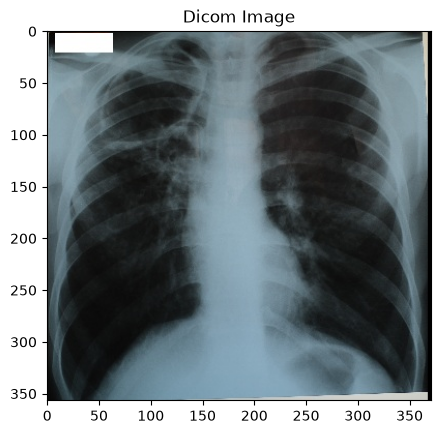

In [102]:
img = dcm.pixel_array
plt.imshow(img, cmap='gray')
plt.title('Dicom Image')
plt.show()

In [48]:
dcm2 = pydicom.dcmread('/Users/Isa/Documents/Curso Medical Image Processing/data/anonym/our_sample_dicom.dcm')
dcm2


Dataset.file_meta -------------------------------
(0002,0000) File Meta Information Group Length  UL: 218
(0002,0001) File Meta Information Version       OB: b'\x00\x01'
(0002,0002) Media Storage SOP Class UID         UI: CT Image Storage
(0002,0003) Media Storage SOP Instance UID      UI: 1.3.46.670589.33.1.63849049636503447100001.4758671761353145811
(0002,0010) Transfer Syntax UID                 UI: JPEG Lossless, Non-Hierarchical, First-Order Prediction (Process 14 [Selection Value 1])
(0002,0012) Implementation Class UID            UI: 1.2.840.113845.1.1
(0002,0013) Implementation Version Name         SH: 'Syn7,3,0,258'
(0002,0016) Source Application Entity Title     AE: 'SynapseDicomSCP'
-------------------------------------------------
(0008,0005) Specific Character Set              CS: 'ISO_IR 100'
(0008,0008) Image Type                          CS: ['DERIVED', 'SECONDARY', 'MPR']
(0008,0012) Instance Creation Date              DA: '20240418'
(0008,0013) Instance Creation Time 

In [49]:
print(f'Patient Name: {dcm2.PatientName}')
print(f'Institution Name : {dcm2.InstitutionName} ')

Patient Name: OurBeloved^Colleague
Institution Name : BovenIJ Ziekenhuis iCT 


### Applying Windowing to the DICOM Images

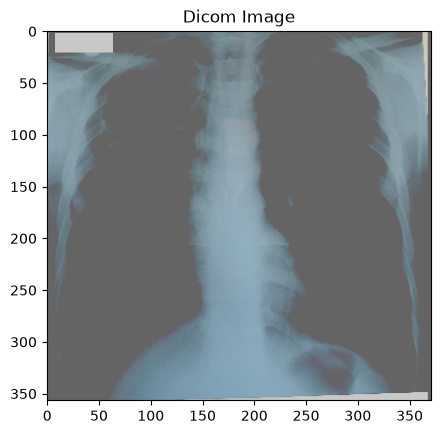

In [108]:
image = dcm.pixel_array # * dcm.RescaleSlope + dcm.RescaleIntercept
image = np.clip(image, 100, 200)
plt.imshow(image, cmap='gray')
plt.title('Dicom Image')
plt.show()

In [51]:
np.save('test/np_dcm_file.npy',image)

### Nibabel

In [52]:
import nibabel as nib
import matplotlib.pyplot as plt

Visualization using Nibabel

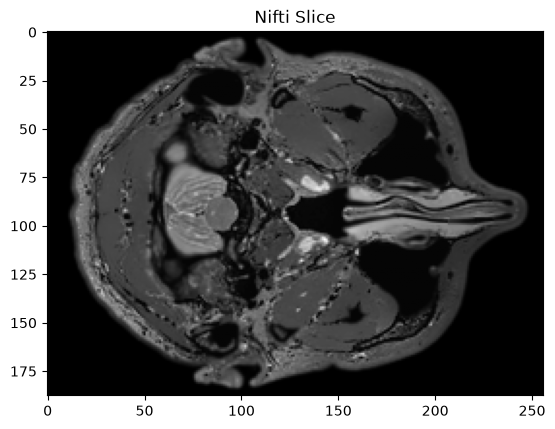

In [92]:
nii = nib.load('/Users/Isa/Documents/Curso Medical Image Processing/data/mri/chris_t2.nii.gz')
nii_array = nii.get_fdata()
plt.imshow(nii_array[:,:,20],cmap='gray') # 20 es la slice que queremos ver
plt.title('Nifti Slice')
plt.show()

Extracting the tags from the MetaData

In [54]:
print(nii.header)

<class 'nibabel.nifti1.Nifti1Header'> object, endian='<'
sizeof_hdr      : 348
data_type       : b''
db_name         : b''
extents         : 0
session_error   : 0
regular         : b''
dim_info        : 0
dim             : [  3 432 432  30   1   1   1   1]
intent_p1       : 0.0
intent_p2       : 0.0
intent_p3       : 0.0
intent_code     : none
datatype        : int16
bitpix          : 16
slice_start     : 0
pixdim          : [1.        0.9259259 0.9259259 5.7360578 0.        0.        0.
 0.       ]
vox_offset      : 0.0
scl_slope       : nan
scl_inter       : nan
slice_end       : 29
slice_code      : unknown
xyzt_units      : 2
cal_max         : 0.0
cal_min         : 0.0
slice_duration  : 0.0
toffset         : 0.0
glmax           : 0
glmin           : 0
descrip         : b'Philips Healthcare Ingenia 5.4.1 '
aux_file        : b''
qform_code      : scanner
sform_code      : unknown
quatern_b       : 0.008265011012554169
quatern_c       : 0.7070584893226624
quatern_d       : -0.70705848

In [56]:
print(f'Data shape: {nii.shape}')
print(f'Voxel size: {nii.header["pixdim"]}')
print(f'Data type: {nii_array.dtype}')

Data shape: (432, 432, 30)
Voxel size: [1.        0.9259259 0.9259259 5.7360578 0.        0.        0.
 0.       ]
Data type: float64


Applying transformation to the nifti file

In [93]:
# The final important piece of metadata associated with an image file is the affine matrix,
# which indicates the position of the image array data in the reference space.
affine = np.array([[1,0,0,0],[0,1,0,0],[0,0,1,0],[0,0,0,1]])
nii.set_qform(affine)
nib.save(nii,'test2/transformed.nii')

### Dicom2Nifti

In [62]:
import dicom2nifti

path_to_dicom = 'path/to/dicom'
dicom2nifti.dicom_series_to_nifti(path_to_dicom,'test/nifti_patient.nii.gz')

### SimpleITK

In [65]:
import SimpleITK as sitk
import matplotlib.pyplot as plt

Visualizing the dicom file using SimpleITK

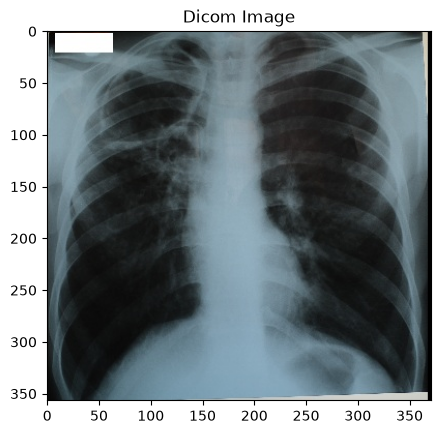

In [69]:
dcm = sitk.ReadImage('/Users/Isa/Documents/Curso Medical Image Processing/data/sitk/digital_xray.dcm')

image = sitk.GetArrayFromImage(dcm)
plt.imshow(image[0], cmap='gray')
plt.title('Dicom Image')
plt.show()

In [70]:
print(dcm)

VectorImage (0x7a04e59200)
  RTTI typeinfo:   itk::VectorImage<unsigned char, 3u>
  Reference Count: 1
  Modified Time: 2652
  Debug: Off
  Object Name: 
  Observers: 
    none
  Source: (none)
  Source output name: (none)
  Release Data: Off
  Data Released: False
  Global Release Data: Off
  PipelineMTime: 2635
  UpdateMTime: 2648
  RealTimeStamp: 0 seconds 
  LargestPossibleRegion: 
    Dimension: 3
    Index: [0, 0, 0]
    Size: [371, 357, 1]
  BufferedRegion: 
    Dimension: 3
    Index: [0, 0, 0]
    Size: [371, 357, 1]
  RequestedRegion: 
    Dimension: 3
    Index: [0, 0, 0]
    Size: [371, 357, 1]
  Spacing: [1, 1, 1]
  Origin: [0, 0, 0]
  Direction: 
1 0 0
0 1 0
0 0 1

  IndexToPointMatrix: 
1 0 0
0 1 0
0 0 1

  PointToIndexMatrix: 
1 0 0
0 1 0
0 0 1

  Inverse Direction: 
1 0 0
0 1 0
0 0 1

  VectorLength: 3
  PixelContainer: 
    ImportImageContainer (0x7a03d04960)
      RTTI typeinfo:   itk::ImportImageContainer<unsigned long, unsigned char>
      Reference Count: 1
      

Extracting the metadata from the dicom using SimpleITK

In [76]:
dcm2 = sitk.ReadImage('/Users/Isa/Documents/Curso Medical Image Processing/data/anonym/our_sample_dicom.dcm')
print(f'Patient Name: {dcm2.GetMetaData('0010|0010')}')

Patient Name: OurBeloved^Colleague


### Numpy-stl

In [79]:
import nibabel as nib
import numpy as np
from stl import mesh
from skimage import measure

In [98]:
file_path = '/Users/Isa/Documents/Curso Medical Image Processing/data/mri/chris_t2.nii.gz'

nifti_file = nib.load(file_path)
np_array = nifti_file.get_fdata()

verts, faces, normals, values = measure.marching_cubes(np_array,0)
obj_3d = mesh.Mesh(np.zeros(faces.shape[0],dtype=mesh.Mesh.dtype))

for i, f in enumerate(faces):
    obj_3d.vectors[i] = verts[f]

obj_3d.save('test2/output_brats.stl')


### ITK

In [81]:
import matplotlib.pyplot as plt
import itk

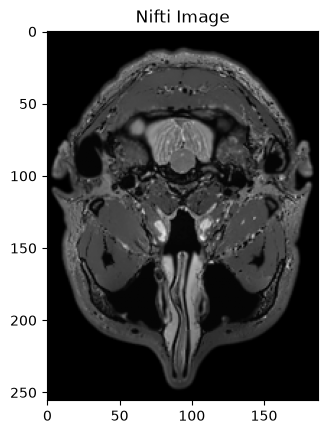

In [95]:
image = itk.imread( '/Users/Isa/Documents/Curso Medical Image Processing/data/mri/chris_t2.nii.gz')
array = itk.array_view_from_image(image)

plt.imshow(array[20], cmap='gray') # slice number 9
plt.title('Nifti Image')
plt.show()

In [96]:
smoothed_image = itk.median_image_filter(image, radius=8)
itk.imwrite(smoothed_image, 'test2/smoothed_image.nii')

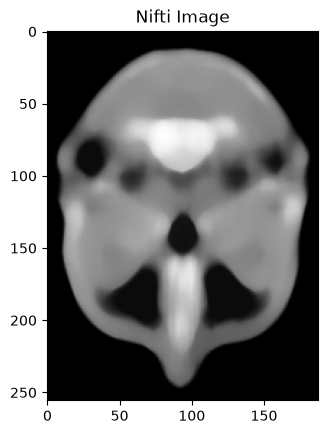

In [97]:
image = itk.imread( 'test2/smoothed_image.nii')
array = itk.array_view_from_image(image)

plt.imshow(array[20], cmap='gray') # slice number 9
plt.title('Nifti Image')
plt.show()